# REAL-CV-2. Сравнение поз по двум фотографиям

**Спринт II · Skillfactory · виртуальный коуч**

Задача: сравнить позу на **`my.jpg`** с позой бегущей девушки из первого спринта.
Получим ключевые точки, совместим их аффинным преобразованием и вычислим
**косинусное сходство** и **взвешенное расстояние**. Результаты реального запуска
сохранены ниже, в разделе «Ответ на задание» и в конце ноутбука.

## Запуск в составе проекта

Это сохранённый учебный этап. Основной пример финальной версии находится в `examples/01_video_comparison.ipynb`.

## 1. Окружение и параметры

Используем ту же Keypoint R-CNN и веса COCO_V1, что в первом спринте.
Из каждой фотографии выбираем человека с максимальным score среди детекций
выше 0.9. Для сопоставления оставляем одноимённые точки, score которых выше 2
**на обоих изображениях**. Порог в 6 общих точек оставляет избыточность для
оценивания аффинного преобразования; отдельно проверяется невырожденность системы.

`keypoints_scores` — оценки тепловых карт, а не вероятности. Третья координата
`keypoints[..., 2]` не заменяет эти оценки. 

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import hashlib
import json
import platform

import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import torch
import torchvision
from PIL import Image, ImageOps
from IPython.display import Markdown, display
from torchvision import transforms as T
from torchvision.models.detection import (
    KeypointRCNN_ResNet50_FPN_Weights,
    keypointrcnn_resnet50_fpn,
)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 14, "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"reference": "#245B9E", "input": "#C26620", "residual": "#757575"}

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "REAL_CV_2_Pose_Comparison.ipynb").is_file():
    PROJECT_DIR = PROJECT_DIR / "examples" / "sprints" / "sprint_2"
REFERENCE_PATH = PROJECT_DIR / "reference_runner.png"
INPUT_PATH = PROJECT_DIR / "my.jpg"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CONF_THRESHOLD = 0.9
KEYPOINT_THRESHOLD = 2.0
MIN_COMMON_KEYPOINTS = 6
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for path in (REFERENCE_PATH, INPUT_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Не найден {path}. Проверьте PROJECT_DIR.")
OUTPUT_DIR.mkdir(exist_ok=True)

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.benchmark = False
versions = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "numpy": np.__version__,
    "opencv": cv2.__version__, "matplotlib": matplotlib.__version__,
}
print("Версии:", versions)
print("Устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Версии: {'python': '3.11.7', 'torch': '2.5.1+cu121', 'torchvision': '0.20.1+cu121', 'numpy': '2.4.6', 'opencv': '4.11.0', 'matplotlib': '3.11.1'}
Устройство: cuda
GPU: NVIDIA GeForce RTX 4070 Ti


## 2. Изображения и предобученная модель

Фотографии переводятся в RGB с учётом EXIF-ориентации. `ToTensor()` переводит
значения в диапазон [0, 1]; дальнейшую нормализацию выполняет сама модель.

In [2]:
def load_rgb(path):
    with Image.open(path) as source:
        return np.array(ImageOps.exif_transpose(source).convert("RGB"))


reference_rgb = load_rgb(REFERENCE_PATH)
input_rgb = load_rgb(INPUT_PATH)
transform = T.Compose([T.ToTensor()])
weights = KeypointRCNN_ResNet50_FPN_Weights.COCO_V1
model = keypointrcnn_resnet50_fpn(weights=weights, progress=False).to(DEVICE).eval()
keypoints = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle",
]
assert keypoints == weights.meta["keypoint_names"]
print("Эталон, H × W × C:", reference_rgb.shape)
print("my.jpg, H × W × C:", input_rgb.shape)
print("Веса:", weights.name, "| Режим обучения:", model.training)

Эталон, H × W × C: (886, 1300, 3)
my.jpg, H × W × C: (682, 1023, 3)
Веса: COCO_V1 | Режим обучения: False


## 3. Извлечение поз

Запускаем модель по одному изображению, чтобы ограничить потребление памяти.
Для каждой выбранной детекции сохраняем все 17 координат и оценки точек.
Стороны `left` и `right` относятся к телу человека, а не к сторонам фотографии.

In [3]:
def predict_person(image_rgb, image_name):
    tensor = transform(image_rgb)
    assert tensor.shape[0] == 3 and tensor.dtype == torch.float32
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    started = perf_counter()
    with torch.inference_mode():
        prediction = model([tensor.to(DEVICE)])[0]
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = perf_counter() - started
    prediction = {name: value.detach().cpu() for name, value in prediction.items()}
    candidates = torch.where(
        (prediction["labels"] == 1) & (prediction["scores"] > CONF_THRESHOLD)
    )[0]
    if not len(candidates):
        raise ValueError(f"{image_name}: нет человека со score > {CONF_THRESHOLD}.")
    person_id = int(candidates[prediction["scores"][candidates].argmax()])
    points = prediction["keypoints"][person_id, :, :2].numpy().astype(np.float64)
    scores = prediction["keypoints_scores"][person_id].numpy().astype(np.float64)
    assert points.shape == (17, 2) and scores.shape == (17,)
    assert np.isfinite(points).all() and np.isfinite(scores).all()
    print(f"{image_name}: кандидатов выше порога — {len(candidates)}; "
          f"выбран id={person_id}, score={prediction['scores'][person_id]:.4f}; "
          f"точек выше порога — {(scores > KEYPOINT_THRESHOLD).sum()}/17; "
          f"инференс — {elapsed:.2f} с")
    return {"prediction": prediction, "person_id": person_id,
            "points": points, "scores": scores, "seconds": elapsed}


reference = predict_person(reference_rgb, "Эталон")
user_pose = predict_person(input_rgb, "my.jpg")

Эталон: кандидатов выше порога — 1; выбран id=0, score=0.9997; точек выше порога — 17/17; инференс — 0.59 с
my.jpg: кандидатов выше порога — 1; выбран id=0, score=0.9999; точек выше порога — 17/17; инференс — 0.09 с


## 4. Визуальная проверка найденных скелетов

Ниже используются функции отрисовки из первого спринта: связь рисуется только
при достаточном score обеих точек. Подписанные изображения позволяют проверить,
на каком человеке и каких суставах основаны дальнейшие вычисления.

In [4]:
def to_numpy(value):
    """Принимает тензор на CPU/GPU или массив NumPy."""
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


def person_colors(count):
    """Один RGB-цвет для каждого человека, общий для точек и линий."""
    cmap = plt.get_cmap("rainbow")
    return [
        tuple(int(channel * 255) for channel in cmap(position)[:3])
        for position in np.linspace(0.1, 0.9, count)
    ]


def draw_keypoints_per_person(
    img, all_keypoints, all_scores, confs,
    keypoint_threshold=2, conf_threshold=0.9,
):
    """Рисует точки людей, прошедших оба порога; исходный RGB-массив не меняет."""
    img_copy = img.copy()
    points = to_numpy(all_keypoints)
    point_scores = to_numpy(all_scores)
    person_scores = to_numpy(confs)
    colors = person_colors(len(points))

    for person_id, person_points in enumerate(points):
        if person_scores[person_id] <= conf_threshold:
            continue
        for point, score in zip(person_points, point_scores[person_id]):
            if score > keypoint_threshold and np.isfinite(point[:2]).all():
                position = tuple(np.rint(point[:2]).astype(int).tolist())
                cv2.circle(img_copy, position, 5, colors[person_id], -1,
                           lineType=cv2.LINE_AA)
    return img_copy


def get_limbs_from_keypoints(keypoints):
    limbs = [
        [keypoints.index("right_eye"), keypoints.index("nose")],
        [keypoints.index("right_eye"), keypoints.index("right_ear")],
        [keypoints.index("left_eye"), keypoints.index("nose")],
        [keypoints.index("left_eye"), keypoints.index("left_ear")],
        [keypoints.index("right_shoulder"), keypoints.index("right_elbow")],
        [keypoints.index("right_elbow"), keypoints.index("right_wrist")],
        [keypoints.index("left_shoulder"), keypoints.index("left_elbow")],
        [keypoints.index("left_elbow"), keypoints.index("left_wrist")],
        [keypoints.index("right_hip"), keypoints.index("right_knee")],
        [keypoints.index("right_knee"), keypoints.index("right_ankle")],
        [keypoints.index("left_hip"), keypoints.index("left_knee")],
        [keypoints.index("left_knee"), keypoints.index("left_ankle")],
        [keypoints.index("right_shoulder"), keypoints.index("left_shoulder")],
        [keypoints.index("right_hip"), keypoints.index("left_hip")],
        [keypoints.index("right_shoulder"), keypoints.index("right_hip")],
        [keypoints.index("left_shoulder"), keypoints.index("left_hip")],
    ]
    return limbs


def draw_skeleton_per_person(
    img, all_keypoints, all_scores, confs, limbs,
    keypoint_threshold=2, conf_threshold=0.9,
):
    """Соединяет надёжные точки и возвращает новое RGB-изображение."""
    img_copy = img.copy()
    points = to_numpy(all_keypoints)
    point_scores = to_numpy(all_scores)
    person_scores = to_numpy(confs)
    colors = person_colors(len(points))

    for person_id, person_points in enumerate(points):
        if person_scores[person_id] <= conf_threshold:
            continue
        for start_id, end_id in limbs:
            if not (
                point_scores[person_id, start_id] > keypoint_threshold
                and point_scores[person_id, end_id] > keypoint_threshold
            ):
                continue
            endpoints = person_points[[start_id, end_id], :2]
            if not np.isfinite(endpoints).all():
                continue
            start, end = [tuple(np.rint(point).astype(int).tolist()) for point in endpoints]
            cv2.line(img_copy, start, end, colors[person_id], 3,
                     lineType=cv2.LINE_AA)

    return draw_keypoints_per_person(
        img_copy, points, point_scores, person_scores,
        keypoint_threshold=keypoint_threshold,
        conf_threshold=conf_threshold,
    )

limbs = get_limbs_from_keypoints(keypoints)

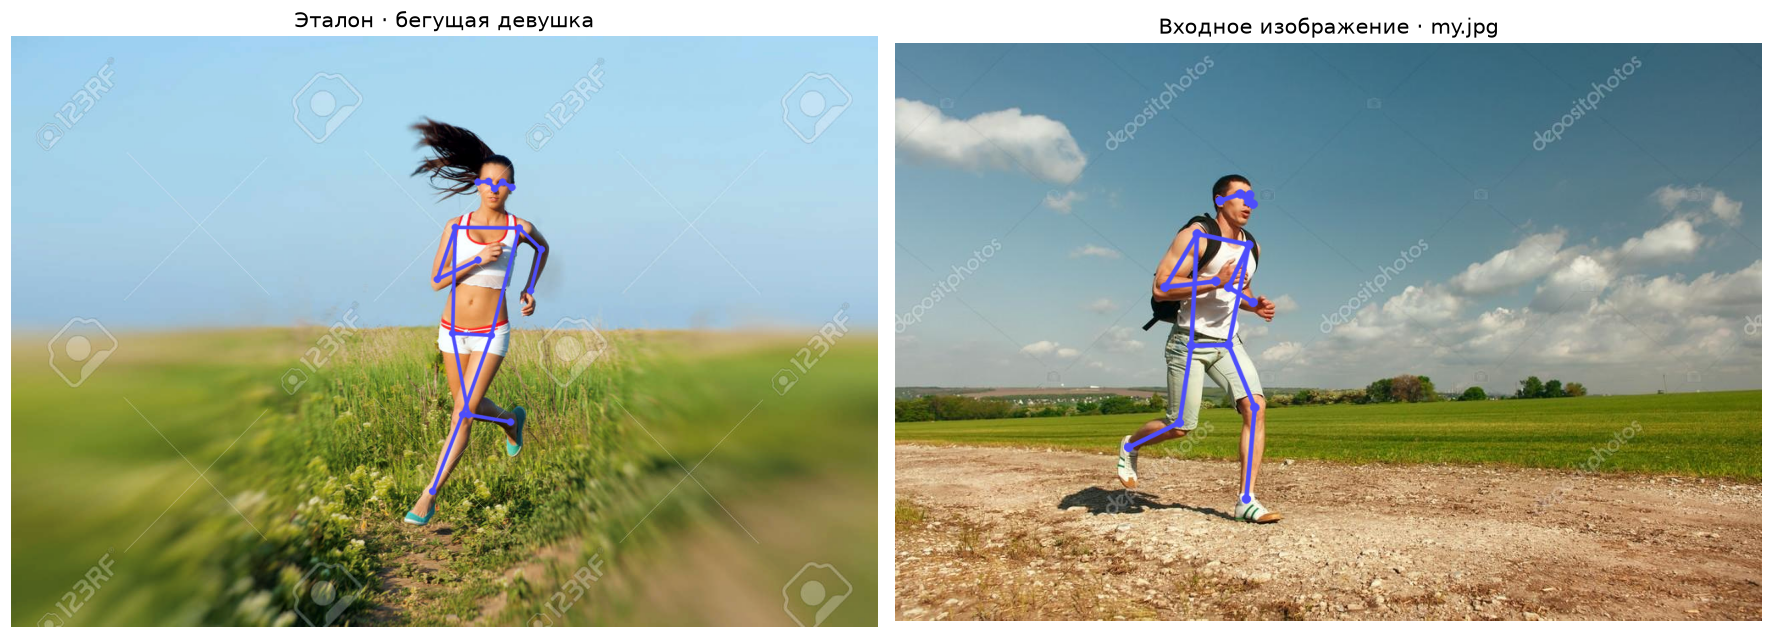

In [5]:
def draw_selected(image_rgb, result):
    prediction = result["prediction"]
    selected = slice(result["person_id"], result["person_id"] + 1)
    return draw_skeleton_per_person(
        image_rgb, prediction["keypoints"][selected],
        prediction["keypoints_scores"][selected], prediction["scores"][selected], limbs,
        keypoint_threshold=KEYPOINT_THRESHOLD, conf_threshold=CONF_THRESHOLD,
    )


reference_skeleton = draw_selected(reference_rgb, reference)
input_skeleton = draw_selected(input_rgb, user_pose)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
for ax, picture, title in zip(
    axes, [reference_skeleton, input_skeleton],
    ["Эталон · бегущая девушка", "Входное изображение · my.jpg"],
):
    ax.imshow(picture)
    ax.set_title(title)
    ax.axis("off")
fig.savefig(OUTPUT_DIR / "01_detected_skeletons.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Общие надёжные точки

Соответствие устанавливается **по названию сустава**, не по близости координат.
Одна и та же маска применяется к эталону, входу и весам. Неуверенные точки
исключаются, а не заменяются нулями. Для метрики курса используем score входной
точки; score эталона участвует в отборе общих точек.

In [6]:
common_mask = (
    (reference["scores"] > KEYPOINT_THRESHOLD)
    & (user_pose["scores"] > KEYPOINT_THRESHOLD)
)
common_ids = np.flatnonzero(common_mask)
common_names = np.asarray(keypoints)[common_mask].tolist()
model_key_points = reference["points"][common_mask]
input_key_points = user_pose["points"][common_mask]
input_confidences = user_pose["scores"][common_mask]
if len(common_ids) < MIN_COMMON_KEYPOINTS:
    raise ValueError(f"Для сравнения осталось только {len(common_ids)} общих точек.")
print(f"Сравниваем общих точек: {len(common_ids)}/17")
print("Исключены:", ", ".join(np.asarray(keypoints)[~common_mask]) or "нет")

rows = ["| Точка | Score эталона | Score my.jpg | В сравнении |",
        "| :--- | ---: | ---: | :---: |"]
for i, name in enumerate(keypoints):
    included = "да" if common_mask[i] else "нет"
    rows.append(f"| {name} | {reference['scores'][i]:.2f} | "
                f"{user_pose['scores'][i]:.2f} | {included} |")
display(Markdown("\n".join(rows)))

Сравниваем общих точек: 17/17
Исключены: нет


| Точка | Score эталона | Score my.jpg | В сравнении |
| :--- | ---: | ---: | :---: |
| nose | 15.77 | 14.01 | да |
| left_eye | 14.49 | 12.99 | да |
| right_eye | 16.60 | 15.56 | да |
| left_ear | 12.04 | 5.34 | да |
| right_ear | 15.82 | 15.82 | да |
| left_shoulder | 8.19 | 10.11 | да |
| right_shoulder | 11.08 | 10.61 | да |
| left_elbow | 7.85 | 9.66 | да |
| right_elbow | 12.02 | 12.92 | да |
| left_wrist | 9.62 | 10.77 | да |
| right_wrist | 15.97 | 17.05 | да |
| left_hip | 13.38 | 8.91 | да |
| right_hip | 13.30 | 6.67 | да |
| left_knee | 16.50 | 10.50 | да |
| right_knee | 6.92 | 9.12 | да |
| left_ankle | 7.71 | 8.57 | да |
| right_ankle | 8.23 | 8.49 | да |

## 6. Аффинное совмещение методом наименьших квадратов

Повторяем метод курса: дополняем координаты единицей, строим `X = pad(input)`
и `Y = pad(reference)`, затем решаем `X @ A ≈ Y` через `np.linalg.lstsq`.
Координаты хранятся в строках, поэтому перенос находится в последней **строке** A.

In [7]:
def pad(points):
    points = np.asarray(points, dtype=np.float64)
    if points.ndim != 2 or points.shape[1] != 2 or not np.isfinite(points).all():
        raise ValueError("Ожидается конечный массив координат формы (N, 2).")
    return np.hstack([points, np.ones((len(points), 1))])


def unpad(points):
    return np.asarray(points)[:, :2]


def fit_affine(input_points, reference_points):
    if np.shape(input_points) != np.shape(reference_points):
        raise ValueError("Наборы должны содержать одинаковое число соответствующих точек.")
    X = pad(input_points)
    Y = pad(reference_points)
    A, residuals, rank, singular_values = np.linalg.lstsq(X, Y, rcond=None)
    if rank < 3:
        raise ValueError("Точки вырождены: аффинное преобразование не определено однозначно.")
    A[np.abs(A) < 1e-10] = 0
    assert np.allclose(A[:, 2], [0, 0, 1], atol=1e-8)
    A[:, 2] = [0, 0, 1]
    return A, int(rank)


A, rank = fit_affine(input_key_points, model_key_points)
input_transform = unpad(pad(input_key_points) @ A)
input_transform_all = unpad(pad(user_pose["points"]) @ A)
linear_scales = np.linalg.svd(A[:2, :2], compute_uv=False)
determinant = float(np.linalg.det(A[:2, :2]))
print("Матрица A (векторы-строки):\n", np.array2string(A, precision=5, suppress_small=True))
print("Ранг X:", rank)
print("Масштабы вдоль главных направлений:", np.round(linear_scales, 4))
print(f"Определитель линейной части: {determinant:.6f}")
if determinant < 0:
    print("В найденное аффинное преобразование входит отражение. Учитывайте это при выводах.")

Матрица A (векторы-строки):
 [[  0.1926    0.10049   0.     ]
 [ -0.11788   1.3138    0.     ]
 [673.32495 -62.07268   1.     ]]
Ранг X: 3
Масштабы вдоль главных направлений: [1.3217 0.2004]
Определитель линейной части: 0.264887


## 7. Метрики из задания

**Косинусное сходство:** `dot(u, v) / (norm(u) * norm(v))`, где массив позы
развёрнут в вектор `[x1, y1, x2, y2, …]`. Результат от −1 до 1; больше — ближе
направления векторов. Значение 1 возможно и для пропорциональных векторов,
а не только для одинаковых координат.

**Взвешенное расстояние:** `sum(w_i * (abs(dx_i) + abs(dy_i))) / sum(w_i)`.
Это взвешенное L1-расстояние по точкам — исправленный вариант цикла с `abs`
из курса, где требовалось накапливать сумму, а не перезаписывать её.
Вес `w_i` — score i-й точки `my.jpg`. В знаменателе сумма весов **точек**, без
дополнительного множителя 2. Единицы — пиксели эталонного изображения;
**меньше — ближе**, ноль означает полное совпадение. Это не процент совпадения.

In [8]:
def cosine_similarity(pose1, pose2):
    first = np.asarray(pose1, dtype=np.float64).reshape(-1)
    second = np.asarray(pose2, dtype=np.float64).reshape(-1)
    if first.shape != second.shape or first.size == 0:
        raise ValueError("Нужны непустые векторы одинакового размера.")
    if not (np.isfinite(first).all() and np.isfinite(second).all()):
        raise ValueError("Координаты должны быть конечными.")
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    if denominator <= np.finfo(float).eps:
        raise ValueError("Косинусное сходство не определено для нулевого вектора.")
    return float(np.clip(np.dot(first, second) / denominator, -1, 1))


def weight_distance(pose1, pose2, conf1):
    first = np.asarray(pose1, dtype=np.float64).reshape(-1, 2)
    second = np.asarray(pose2, dtype=np.float64).reshape(-1, 2)
    confidences = np.asarray(conf1, dtype=np.float64)
    if first.shape != second.shape or confidences.shape != (len(first),):
        raise ValueError("Одному суставу должны соответствовать две координаты и один вес.")
    if not all(np.isfinite(x).all() for x in (first, second, confidences)):
        raise ValueError("Входы должны быть конечными.")
    if np.any(confidences < 0) or confidences.sum() <= 0:
        raise ValueError("Веса должны быть неотрицательными с положительной суммой.")
    per_point_l1 = np.abs(first - second).sum(axis=1)
    return float(np.dot(confidences, per_point_l1) / confidences.sum())

## 8. Ответ на задание

Основные две метрики вычисляем **после** аффинного совмещения. Дополнительно
показываем косинус для центрированных поз и L1, делённое на высоту набора опорных
точек эталона. Центрирование уменьшает влияние большого общего смещения от начала
координат; нормировка расстояния позволяет понимать его относительно размера позы.

In [10]:
cosine_score = cosine_similarity(model_key_points, input_transform)
weighted_score = weight_distance(model_key_points, input_transform, input_confidences)
model_centered = model_key_points - model_key_points.mean(axis=0)
input_centered = input_transform - input_transform.mean(axis=0)
centered_cosine = cosine_similarity(model_centered, input_centered)
reference_pose_height = float(np.ptp(model_key_points[:, 1]))
if reference_pose_height <= 0:
    raise ValueError("Нулевая высота опорных точек эталона.")
normalized_weighted = weighted_score / reference_pose_height
metrics = {
    "cosine_similarity_after_affine": cosine_score,
    "weighted_l1_reference_px": weighted_score,
    "centered_cosine_similarity_after_affine": centered_cosine,
    "weighted_l1_per_reference_pose_height": normalized_weighted,
    "reference_pose_height_px": reference_pose_height,
    "common_keypoints": int(common_mask.sum()),
}
display(Markdown(
    "| Метрика | Значение | Как читать |\n"
    "| :--- | ---: | :--- |\n"
    f"| **Косинусное сходство (задание)** | **{cosine_score:.6f}** | ближе к 1 — ближе направления |\n"
    f"| **Взвешенное L1-расстояние (задание)** | **{weighted_score:.3f} px** | ближе к 0 — меньше ошибка |\n"
    f"| Косинусное сходство после центрирования | {centered_cosine:.6f} | контроль влияния начала координат |\n"
    f"| Взвешенное L1 / высота позы эталона | {normalized_weighted:.6f} | относительная величина ошибки |"
))
print(f"Общих точек: {len(common_ids)}; высота опорных точек эталона: {reference_pose_height:.1f} px")

| Метрика | Значение | Как читать |
| :--- | ---: | :--- |
| **Косинусное сходство (задание)** | **0.998519** | ближе к 1 — ближе направления |
| **Взвешенное L1-расстояние (задание)** | **41.163 px** | ближе к 0 — меньше ошибка |
| Косинусное сходство после центрирования | 0.956318 | контроль влияния начала координат |
| Взвешенное L1 / высота позы эталона | 0.088501 | относительная величина ошибки |

Общих точек: 17; высота опорных точек эталона: 465.1 px


## 9. Наложение поз после совмещения

Синий каркас — эталон, оранжевый пунктир — преобразованный `my.jpg`.
Серые отрезки соединяют одноимённые точки и показывают оставшуюся ошибку.
Оси имеют один масштаб; направление y вниз соответствует координатам изображения.

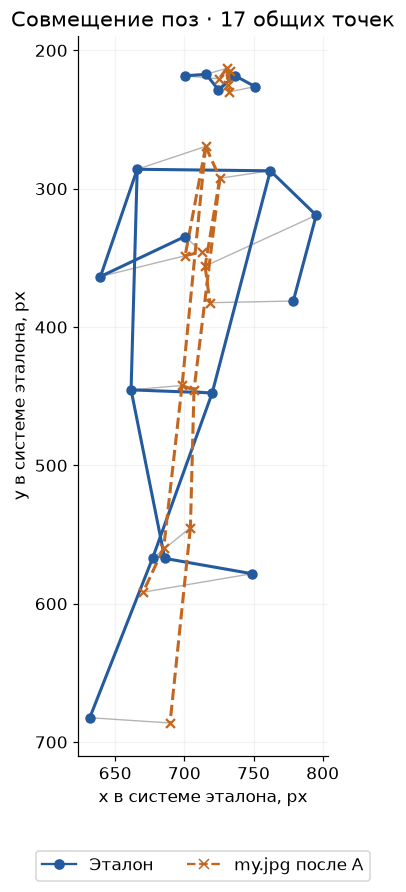

In [11]:
def plot_pose(ax, points, mask, color, linestyle, marker):
    for start_id, end_id in limbs:
        if mask[start_id] and mask[end_id]:
            ax.plot(points[[start_id, end_id], 0], points[[start_id, end_id], 1],
                    color=color, linestyle=linestyle, linewidth=2)
    ax.scatter(points[mask, 0], points[mask, 1], c=color, marker=marker, s=34, zorder=3)


fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
for original, aligned in zip(model_key_points, input_transform):
    ax.plot([original[0], aligned[0]], [original[1], aligned[1]],
            color=COLORS["residual"], linewidth=0.9, alpha=0.55)
plot_pose(ax, reference["points"], common_mask, COLORS["reference"], "-", "o")
plot_pose(ax, input_transform_all, common_mask, COLORS["input"], "--", "x")
ax.set_aspect("equal", adjustable="box")
ax.invert_yaxis()
ax.set_xlabel("x в системе эталона, px")
ax.set_ylabel("y в системе эталона, px")
ax.set_title(f"Совмещение поз · {len(common_ids)} общих точек")
ax.grid(alpha=0.15)
ax.legend(handles=[
    Line2D([0], [0], color=COLORS["reference"], marker="o", label="Эталон"),
    Line2D([0], [0], color=COLORS["input"], linestyle="--", marker="x", label="my.jpg после A"),
], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.savefig(OUTPUT_DIR / "02_aligned_poses.png", dpi=150, bbox_inches="tight")
plt.show()

### Где остаются различия

Для каждого сустава отдельно показываем евклидово расстояние между точками
после совмещения. Это диагностическая L2-ошибка в пикселях, **не** взвешенная
L1-метрика из задания. Она отражает одновременно различия поз, ракурса,
пропорций тела и возможные ошибки детектора.

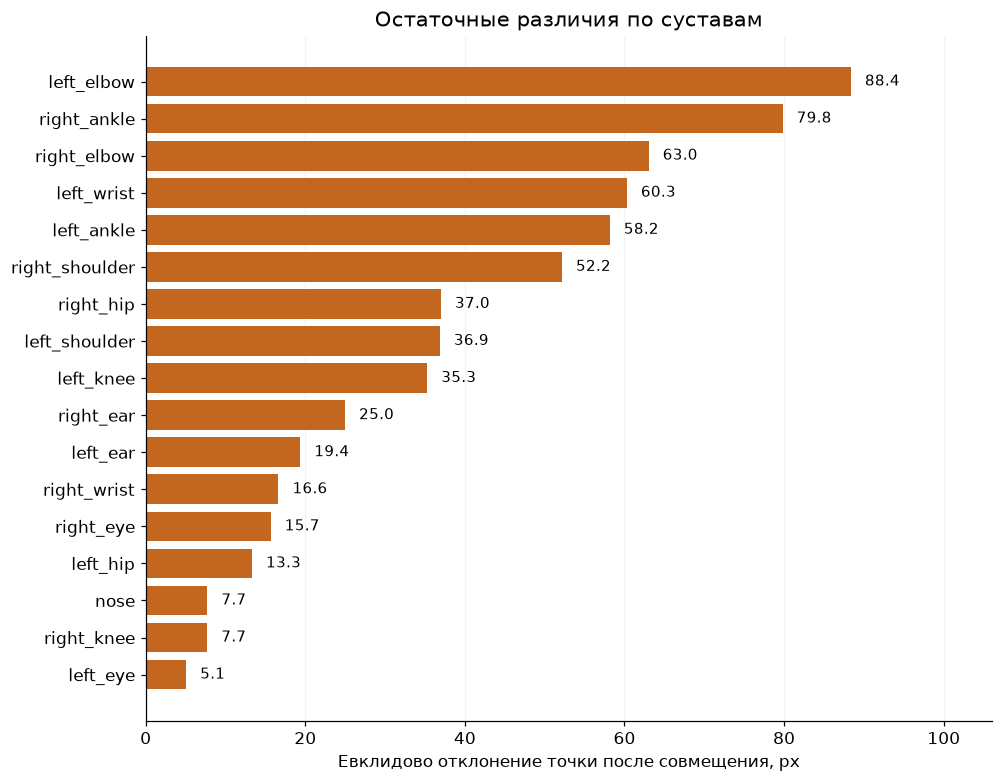

In [12]:
point_l2 = np.linalg.norm(input_transform - model_key_points, axis=1)
point_l1 = np.abs(input_transform - model_key_points).sum(axis=1)
normalized_weights = input_confidences / input_confidences.sum()
assert np.isclose(np.dot(normalized_weights, point_l1), weighted_score)
order = np.argsort(point_l2)[::-1]
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
ax.barh(np.asarray(common_names)[order], point_l2[order], color=COLORS["input"])
ax.invert_yaxis()
ax.set_xlim(0, max(1.0, point_l2.max() * 1.2))
for rank_id, value in enumerate(point_l2[order]):
    ax.text(value + point_l2.max() * 0.02, rank_id, f"{value:.1f}", va="center", fontsize=10)
ax.set_xlabel("Евклидово отклонение точки после совмещения, px")
ax.set_title("Остаточные различия по суставам")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.savefig(OUTPUT_DIR / "03_joint_errors.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Сохранение для следующих спринтов

Сохраняем исходные и преобразованные координаты, маску общих точек, веса,
аффинную матрицу, метрики и изображения. JSON содержит также параметры, версии
и SHA-256 исходных файлов. В CSV одна строка соответствует одному из 17 суставов;
метрики исключённых точек остаются пустыми. NPZ читается без `allow_pickle=True`.

In [13]:
Image.fromarray(reference_skeleton).save(OUTPUT_DIR / "reference_skeleton.png")
Image.fromarray(input_skeleton).save(OUTPUT_DIR / "my_skeleton.png")
np.savez_compressed(
    OUTPUT_DIR / "pose_comparison.npz",
    reference_keypoints=reference["points"], input_keypoints=user_pose["points"],
    reference_keypoint_scores=reference["scores"], input_keypoint_scores=user_pose["scores"],
    transformed_input_keypoints=input_transform_all, affine_matrix=A,
    common_mask=common_mask, keypoint_names=np.asarray(keypoints), limbs=np.asarray(limbs),
)
run_info = {
    "inputs": {path.name: {"sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
               for path in (REFERENCE_PATH, INPUT_PATH)},
    "assignment_files": [f"Course _ Skillfactory{i}.mhtml" for i in range(1, 5)],
    "model": "keypointrcnn_resnet50_fpn", "weights": weights.name,
    "device": str(DEVICE), "versions": versions,
    "conf_threshold": CONF_THRESHOLD, "keypoint_threshold": KEYPOINT_THRESHOLD,
    "minimum_common_keypoints": MIN_COMMON_KEYPOINTS,
    "reference_person_id": reference["person_id"], "input_person_id": user_pose["person_id"],
    "reference_person_score": float(reference["prediction"]["scores"][reference["person_id"]]),
    "input_person_score": float(user_pose["prediction"]["scores"][user_pose["person_id"]]),
    "alignment": "unweighted full affine least squares, input @ A to reference",
    "affine_matrix": A.tolist(), "linear_determinant": determinant,
    "linear_principal_scales": linear_scales.tolist(), "design_rank": rank,
    "metric_weights": "input keypoints_scores, only jointly confident keypoints",
    "weighted_distance_definition": "sum(w * (abs(dx) + abs(dy))) / sum(w)",
    "metrics": metrics,
}
(OUTPUT_DIR / "comparison_results.json").write_text(
    json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8",
)
rows = []
for i, name in enumerate(keypoints):
    record = {
        "keypoint": name, "included": bool(common_mask[i]),
        "reference_x": reference["points"][i, 0], "reference_y": reference["points"][i, 1],
        "input_x": user_pose["points"][i, 0], "input_y": user_pose["points"][i, 1],
        "aligned_x": input_transform_all[i, 0], "aligned_y": input_transform_all[i, 1],
        "reference_score": reference["scores"][i], "input_score": user_pose["scores"][i],
        "error_l1_px": "", "error_l2_px": "", "normalized_weight": "",
    }
    if common_mask[i]:
        position = int(np.flatnonzero(common_ids == i)[0])
        record.update(error_l1_px=point_l1[position], error_l2_px=point_l2[position],
                      normalized_weight=normalized_weights[position])
    rows.append(record)
with (OUTPUT_DIR / "keypoint_comparison.csv").open("w", encoding="utf-8-sig", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
print("Результаты сохранены в:", OUTPUT_DIR.relative_to(PROJECT_DIR))
print("Основные данные: comparison_results.json, pose_comparison.npz, keypoint_comparison.csv")

Результаты сохранены в: outputs
Основные данные: comparison_results.json, pose_comparison.npz, keypoint_comparison.csv


## Вывод

Числа и названия суставов в следующей ячейке вычислены по выполненному запуску.
Высокое косинусное сходство в пиксельных координатах не следует читать как
процент совпадения поз или как оценку правильности упражнения.

In [14]:
largest = "; ".join(f"{common_names[i]} — {point_l2[i]:.1f} px" for i in order[:3])
reflection_note = (
    "Найденная аффинная матрица включает отражение. "
    if determinant < 0 else "Линейная часть найденной матрицы не включает отражение. "
)
display(Markdown(
    f"На двух фотографиях сопоставлено **{len(common_ids)} из 17** одноимённых точек. "
    f"После аффинного совмещения косинусное сходство составляет **{cosine_score:.6f}**, "
    f"взвешенное L1-расстояние — **{weighted_score:.3f} px**.\n\n"
    f"После центрирования косинусное сходство равно **{centered_cosine:.6f}**. "
    f"Отношение взвешенного L1 к высоте опорных точек эталона — **{normalized_weighted:.6f}**. "
    f"Наибольшие остаточные L2-отклонения: {largest}.\n\n"
    + reflection_note +
    f"Масштабы вдоль главных направлений — {linear_scales[0]:.3f} и {linear_scales[1]:.3f}; "
    f"их отношение — {linear_scales[0] / linear_scales[1]:.2f}. "
    "На наложении видны сжатие входного каркаса и остаточные различия рук и ног. "
    "Общее аффинное преобразование может сгладить различия формы за счёт "
    "неравномерного масштабирования и shear. Кроме самой позы, на результат "
    "влияют ракурс съёмки, пропорции тела и ошибки обнаружения суставов. "
    "По этим двум изображениям и без размеченной выборки нельзя обосновать "
    "универсальный порог «упражнение выполнено правильно».\n\n"
    "Задание выполнено: позы извлечены, аффинно совмещены, обе метрики рассчитаны, "
    "результаты и координаты сохранены для следующего спринта."
))

На двух фотографиях сопоставлено **17 из 17** одноимённых точек. После аффинного совмещения косинусное сходство составляет **0.998519**, взвешенное L1-расстояние — **41.163 px**.

После центрирования косинусное сходство равно **0.956318**. Отношение взвешенного L1 к высоте опорных точек эталона — **0.088501**. Наибольшие остаточные L2-отклонения: left_elbow — 88.4 px; right_ankle — 79.8 px; right_elbow — 63.0 px.

Линейная часть найденной матрицы не включает отражение. Масштабы вдоль главных направлений — 1.322 и 0.200; их отношение — 6.60. На наложении видны сжатие входного каркаса и остаточные различия рук и ног. Общее аффинное преобразование может сгладить различия формы за счёт неравномерного масштабирования и shear. Кроме самой позы, на результат влияют ракурс съёмки, пропорции тела и ошибки обнаружения суставов. По этим двум изображениям и без размеченной выборки нельзя обосновать универсальный порог «упражнение выполнено правильно».

Задание выполнено: позы извлечены, аффинно совмещены, обе метрики рассчитаны, результаты и координаты сохранены для следующего спринта.